# Homography: matrices, validity and reprojection error

This notebook explores both homography CSVs locally. Each valid row contains a 3×3 matrix that maps normalised pitch coordinates `(x, y)` to pixels in that recording.

Homography is useful when combining tracking with video pixels. It is optional for a tracking-only first model because the ATD already uses pitch coordinates.

> Keep notebook outputs local and clear them before committing.

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def find_repo_root(start=Path.cwd()):
    for candidate in (start, *start.parents):
        if (candidate / 'games.py').exists() and (candidate / 'DATA.md').exists():
            return candidate
    raise FileNotFoundError('Could not find repository root')

ROOT = find_repo_root()
DATA_ROOT = Path(os.environ.get('MTAH_DATA_DIR', ROOT / 'data'))
FPS = 25
MATRIX_COLUMNS = [f'h{row}{column}' for row in range(3) for column in range(3)]

def locate(source, filename):
    candidates = [DATA_ROOT / source / filename, DATA_ROOT / filename]
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError(f'Could not find {filename} in {candidates}')

## 1. Load both timelines separately

Tactical rows correspond directly to submission frames. Broadcast rows belong to the independent broadcast timeline and must not be treated as tactical frame numbers.

In [2]:
homographies = {}
for source in ('tactical', 'broadcast'):
    path = locate(source, f'BAR-ATH_{source}_homography.csv')
    frame = pd.read_csv(path)
    homographies[source] = frame
    print(f'{source}: {len(frame):,} rows × {len(frame.columns)} columns — {path.name}')
    display(frame.head(5))

tactical: 199,319 rows × 12 columns — BAR-ATH_tactical_homography.csv


,frame,h00,h01,h02,h10,h11,h12,h20,h21,h22,reprojection_error,valid
0,0,1834.51428,-519.781433,45.983478,5.733814,162.882401,256.334229,-0.008851,-0.534427,1,0.589505,1
1,1,1834.55481,-519.716187,45.878456,5.647519,162.892273,256.363373,-0.008816,-0.534435,1,0.574035,1
2,2,1834.59546,-519.650940,45.773430,5.561231,162.902145,256.392517,-0.008781,-0.534442,1,0.558565,1
3,3,1834.63599,-519.585693,45.668427,5.474893,162.912003,256.421692,-0.008746,-0.534450,1,0.543095,1
4,4,1834.67651,-519.520447,45.563393,5.388579,162.921890,256.450836,-0.008711,-0.534458,1,0.527626,1


broadcast: 164,488 rows × 12 columns — BAR-ATH_broadcast_homography.csv


,frame,h00,h01,h02,h10,h11,h12,h20,h21,h22,reprojection_error,valid
0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-100.0,0
1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-100.0,0
2,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-100.0,0
3,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-100.0,0
4,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-100.0,0


## 2. Schema and integrity checks

Expected columns are `frame`, nine matrix coefficients `h00...h22`, `reprojection_error`, and `valid`. A valid row should have all nine coefficients.

In [3]:
for source, frame in homographies.items():
    print(f'\n{source.upper()} columns')
    schema = pd.DataFrame({
        'dtype': frame.dtypes.astype(str),
        'missing': frame.isna().sum(),
        'missing_pct': (100 * frame.isna().mean()).round(2),
        'unique': frame.nunique(dropna=True),
    })
    display(schema)


TACTICAL columns


,dtype,missing,missing_pct,unique
frame,int64,0,0.0,199319
h00,float64,0,0.0,191781
h01,float64,0,0.0,192481
h02,float64,0,0.0,195424
h10,float64,0,0.0,195973
h11,float64,0,0.0,193840
h12,float64,0,0.0,192965
h20,float64,0,0.0,195599
h21,float64,0,0.0,188024
h22,int64,0,0.0,1



BROADCAST columns


,dtype,missing,missing_pct,unique
frame,int64,0,0.00,164488
h00,float64,56240,34.19,107800
h01,float64,56240,34.19,108105
h02,float64,56240,34.19,108132
h10,float64,56240,34.19,108159
h11,float64,56240,34.19,107877
h12,float64,56240,34.19,107962
h20,float64,56240,34.19,108134
h21,float64,56240,34.19,106908
h22,float64,56240,34.19,1


In [4]:
rows = []
for source, frame in homographies.items():
    missing_required = sorted(set(['frame', 'valid', 'reprojection_error', *MATRIX_COLUMNS]) - set(frame.columns))
    frame_ids = frame['frame'].to_numpy() if 'frame' in frame else np.array([])
    valid = frame['valid'].astype(bool) if 'valid' in frame else pd.Series(False, index=frame.index)
    matrix_complete = frame[MATRIX_COLUMNS].notna().all(axis=1) if not missing_required else pd.Series(False, index=frame.index)
    rows.append({
        'source': source,
        'rows': len(frame),
        'first_frame': int(frame_ids[0]) if len(frame_ids) else None,
        'last_frame': int(frame_ids[-1]) if len(frame_ids) else None,
        'contiguous_frames': bool(len(frame_ids) and np.all(np.diff(frame_ids) == 1)),
        'duplicate_frames': int(frame['frame'].duplicated().sum()) if 'frame' in frame else None,
        'valid_pct': round(100 * valid.mean(), 2),
        'valid_rows_missing_matrix': int((valid & ~matrix_complete).sum()),
        'missing_required_columns': ', '.join(missing_required),
    })
display(pd.DataFrame(rows))

,source,rows,first_frame,last_frame,contiguous_frames,duplicate_frames,valid_pct,valid_rows_missing_matrix,missing_required_columns
0,tactical,199319,0,199318,True,0,100.00,0,
1,broadcast,164488,0,164487,True,0,65.81,0,


## 3. Validity over time

The tactical camera normally shows the pitch continuously. The broadcast feed contains cuts, replays and close-ups, so many broadcast frames cannot have a meaningful pitch homography.

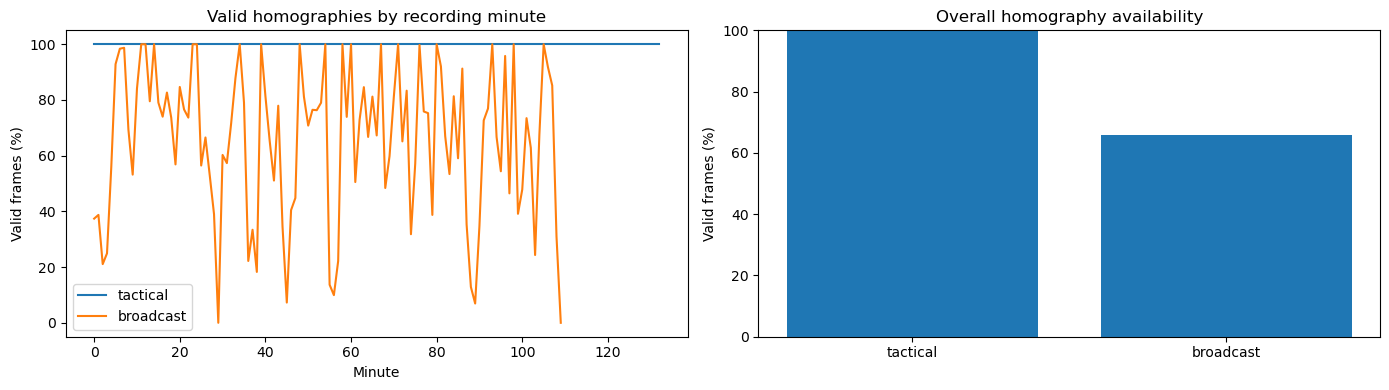

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for source, frame in homographies.items():
    minute = (frame['frame'] // (FPS * 60)).astype(int)
    validity = frame.assign(minute=minute).groupby('minute')['valid'].mean() * 100
    axes[0].plot(validity.index, validity.values, label=source)

valid_pct = pd.Series({source: 100 * frame['valid'].astype(bool).mean()
                       for source, frame in homographies.items()})
axes[1].bar(valid_pct.index, valid_pct.values)
axes[1].set_ylim(0, 100)
axes[0].set(title='Valid homographies by recording minute', xlabel='Minute', ylabel='Valid frames (%)')
axes[1].set(title='Overall homography availability', ylabel='Valid frames (%)')
axes[0].legend()
fig.tight_layout()
plt.show()

## 4. Reprojection-error distributions

Lower reprojection error means the fitted pitch-to-image transform agreed more closely with its calibration evidence. Large values should be treated cautiously even when `valid=1`.

In [6]:
error_rows = []
for source, frame in homographies.items():
    errors = frame.loc[frame['valid'].astype(bool), 'reprojection_error'].dropna()
    error_rows.append({
        'source': source, 'observations': len(errors),
        'min': errors.min(), 'median': errors.median(), 'mean': errors.mean(),
        'p90': errors.quantile(0.90), 'p99': errors.quantile(0.99), 'max': errors.max(),
    })
display(pd.DataFrame(error_rows).round(3))

,source,observations,min,median,mean,p90,p99,max
0,tactical,199319,0.062,0.239,0.423,0.407,4.808,5.476
1,broadcast,108248,-74.952,0.217,0.673,0.450,6.527,303.824


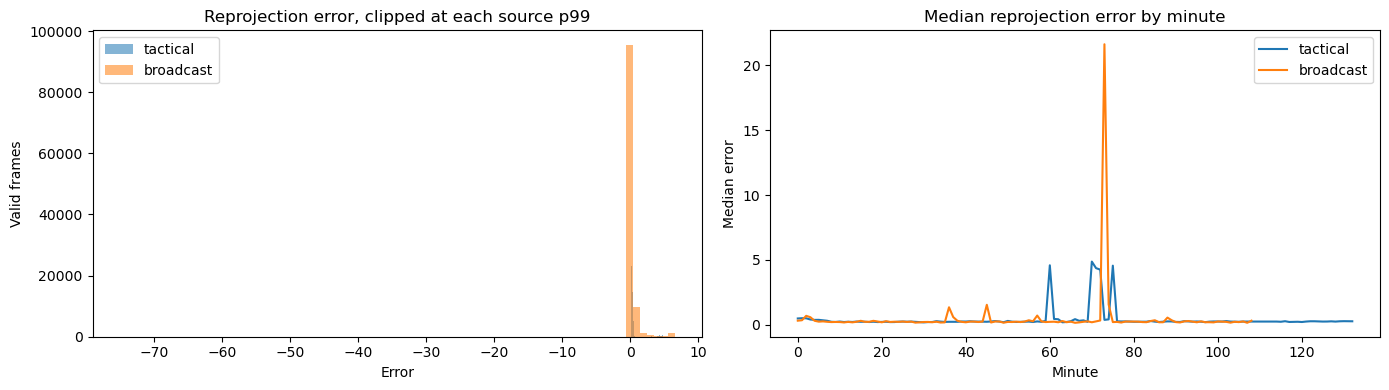

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for source, frame in homographies.items():
    valid_rows = frame[frame['valid'].astype(bool)].copy()
    errors = valid_rows['reprojection_error'].dropna()
    upper = errors.quantile(0.99)
    axes[0].hist(errors.clip(upper=upper), bins=80, alpha=0.55, label=source)
    valid_rows['minute'] = (valid_rows['frame'] // (FPS * 60)).astype(int)
    by_minute = valid_rows.groupby('minute')['reprojection_error'].median()
    axes[1].plot(by_minute.index, by_minute.values, label=source)
axes[0].set(title='Reprojection error, clipped at each source p99', xlabel='Error', ylabel='Valid frames')
axes[1].set(title='Median reprojection error by minute', xlabel='Minute', ylabel='Median error')
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

## 5. What a matrix does

The example below selects the first complete valid tactical matrix and projects the four normalised pitch corners plus the centre into pixels. No MP4 is required for the calculation.

In [8]:
def project(matrix, x, y):
    point = matrix @ np.array([x, y, 1.0])
    return point[0] / point[2], point[1] / point[2]

tactical = homographies['tactical']
complete = tactical['valid'].astype(bool) & tactical[MATRIX_COLUMNS].notna().all(axis=1)
example = tactical.loc[complete].iloc[0]
matrix = example[MATRIX_COLUMNS].to_numpy(dtype=float).reshape(3, 3)
pitch_points = {'top_left': (0, 0), 'top_right': (1, 0),
                'bottom_left': (0, 1), 'bottom_right': (1, 1), 'centre': (0.5, 0.5)}
projected = pd.DataFrame([
    {'point': name, 'pitch_x': x, 'pitch_y': y,
     'pixel_x': project(matrix, x, y)[0], 'pixel_y': project(matrix, x, y)[1]}
    for name, (x, y) in pitch_points.items()
])
print('Example tactical frame:', int(example['frame']))
display(pd.DataFrame(matrix, columns=['col0', 'col1', 'col2'], index=['row0', 'row1', 'row2']))
display(projected.round(2))

Example tactical frame: 0


,col0,col1,col2
row0,1834.514280,-519.781433,45.983478
row1,5.733814,162.882401,256.334229
row2,-0.008851,-0.534427,1.000000


,point,pitch_x,pitch_y,pixel_x,pixel_y
0,top_left,0.0,0.0,45.98,256.33
1,top_right,1.0,0.0,1897.29,264.41
2,bottom_left,0.0,1.0,-1017.67,900.43
3,bottom_right,1.0,1.0,2979.31,930.43
4,centre,0.5,0.5,965.66,467.68


## What Person 1 should take from this

For a tracking-only feature pipeline, retain `valid` and `reprojection_error` only if you intend to add image-space features later. Do not convert tracking positions to pixels merely to convert them back again. If video features are added, check `valid` first and treat reprojection error as a quality indicator.

---

**Before committing:** restart the kernel, clear every output, and save.